0. Intialisation

In [5]:

%load_ext autoreload
%autoreload 2
%reload_ext autoreload

import os
os.chdir(r'C:\Users\benjo\Documents\Projects\ecg-risk-stratification')
print(os.getcwd())




The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
C:\Users\benjo\Documents\Projects\ecg-risk-stratification


1. Load data

In [8]:
from src.external_data import build_labels,cache_signal

df = build_labels('data/physionet')
cached_df = cache_signal(df, out='data/cache_physionet')


Kept 4285/4285 records


1. 1 Load newly cached data

In [13]:
import pandas as pd
from torch.utils.data import DataLoader
from src.dataset import CachedECGDataset

df = pd.read_csv(
    'data/cache_physionet/labels.csv',
    index_col='ecg_id')

external_dataset = CachedECGDataset(
    df,
    cache_dir='data/cache_physionet')

external_loader = DataLoader(
    external_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0)



2. Model Setup 

In [14]:
import torch
from src.model import simpleECGNN
from src.training import eval

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = simpleECGNN(dropout=0.3).to(device)

model.load_state_dict(
    torch.load(
        'results/models/best_simple_cnn.pt',
        map_location=device,
        weights_only=True
    )
)
criterion = torch.nn.BCEWithLogitsLoss()
metrics, labels, probabilities, predictions = eval(
    model,
    external_loader,
    criterion,
    device,
    threshold=0.377286
)

print(metrics)

{'loss': 0.3611953226103944, 'accuracy': 0.8760793465577597, 'auroc': 0.934152322567798, 'auprc': 0.9730541302045278, 'f1': 0.9088724901321434, 'confusion_matrix': array([[1106,  260],
       [ 271, 2648]])}


3. Plotting

Confusion Matrix

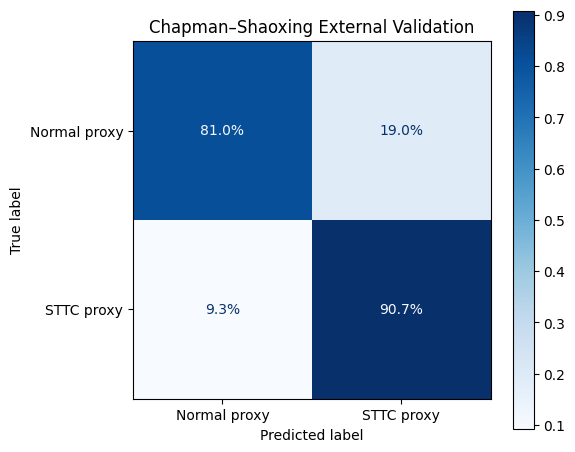

In [15]:
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

plot_dir = Path("results/plots")
plot_dir.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    labels,
    predictions,
    display_labels=["Normal proxy", "STTC proxy"],
    normalize="true",
    cmap="Blues",
    values_format=".1%",
    ax=ax
)

ax.set_title("Chapman–Shaoxing External Validation")
plt.tight_layout()
plt.savefig(plot_dir / "external_confusion_matrix.png", dpi=300)
plt.show()

Final Comparison

In [17]:
import pandas as pd

tn, fp, fn, tp = metrics["confusion_matrix"].ravel()

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "AUROC",
        "AUPRC",
        "F1",
        "Sensitivity",
        "Specificity"
    ],
    "PTB-XL": [
        0.9204, 0.9742, 0.9635,
        0.8925, 0.9079, 0.9276
    ],
    "Chapman_Shaoxing": [
        metrics["accuracy"],
        metrics["auroc"],
        metrics["auprc"],
        metrics["f1"],
        tp / (tp + fn),
        tn / (tn + fp)
    ]
})

comparison["Difference"] = (comparison["Chapman_Shaoxing"] - comparison["PTB-XL"])
display(comparison.round(4))
Path("results/metrics").mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    "results/metrics/external_comparison.csv",
    index=False
)

,Metric,PTB-XL,Chapman_Shaoxing,Difference
0,Accuracy,0.9204,0.8761,-0.0443
1,AUROC,0.9742,0.9342,-0.0400
2,AUPRC,0.9635,0.9731,0.0096
3,F1,0.8925,0.9089,0.0164
4,Sensitivity,0.9079,0.9072,-0.0007
5,Specificity,0.9276,0.8097,-0.1179
